# Homework 07: Ensemble Methods – Gradient Boosting

#### Due: **Sunday, October 18th** @ 11:59 PM (with 2 hour & 1 minute grace period)

Over the past two weeks, we have expanded our machine learning toolkit from linear regression to decision trees and ensemble methods. In Homework 06, you explored how the hyperparameters of a decision tree affect its complexity and generalization performance, using **independent manual sweeps and cross-validation** to guide your experiments.

This week, we will focus on **Gradient Boosting**, a powerful ensemble method that builds a sequence of decision trees, each designed to improve upon the predictions of the preceding ensemble.

Gradient boosting introduces several important hyperparameters, including the number of boosting stages, the learning rate, and the complexity of the individual trees. These parameters can interact, making systematic tuning particularly important.

In this homework, we will extend the manual tuning techniques from Homework 06 by introducing **two automated hyperparameter search methods: `RandomizedSearchCV` and `GridSearchCV`**.

### What We Will Do in This Homework

Our goal is not simply to find the model with the lowest prediction error. We also want to understand **how hyperparameters affect performance, how they interact, and how to balance predictive accuracy against computational cost**.

We will proceed through five stages:

1. **Establish a Baseline (Problem 1)**

   Train a `GradientBoostingRegressor` using its default hyperparameters and establish a baseline cross-validation MAE.

2. **Explore Individual Hyperparameters (Problem 2)**

   Use independent manual sweeps to investigate five important hyperparameters:

   - `n_estimators`
   - `max_depth`
   - `learning_rate`
   - `min_samples_leaf`
   - `subsample`

   For each parameter, examine plots of training and cross-validation MAE, identify promising values, and observe when additional model complexity produces diminishing returns.

3. **Explore Hyperparameter Combinations (Problem 3)**

   Use `RandomizedSearchCV` to sample combinations from a broad hyperparameter space.

   This allows us to investigate **interactions between hyperparameters**, such as the relationship between `learning_rate` and `n_estimators`, without evaluating every possible combination.

4. **Refine a Promising Configuration (Problem 4)**

   Use `GridSearchCV` to systematically explore a smaller region identified by randomized search.

   We will compare the improvement obtained with the additional computational cost and consider whether more extensive tuning is worthwhile.

5. **Select and Evaluate the Final Model (Problem 5)**

   Compare the baseline, randomized-search, and grid-search configurations using a consistent cross-validation procedure.

   Select the configuration with the lowest mean CV MAE, train a fresh model on the complete training set, and evaluate it **once on the held-out test set**.

Finally, **Problem 6** contains conceptual multiple-choice questions, and **Problem 7** asks you to reflect on the tradeoffs between model performance, complexity, and computational cost.

### Hyperparameter Interactions and Diminishing Returns

Two important ideas will recur throughout this homework.

**First, hyperparameters can interact.** For example, lowering `learning_rate` reduces the contribution of each new tree, so a larger `n_estimators` may be needed to achieve good predictive performance. The best combination is not necessarily obtained by selecting the best value of each parameter independently.

**Second, more complexity does not always produce meaningful improvements.** As additional boosting stages are added, training MAE may continue to decrease while CV MAE levels off. We need not wait for CV MAE to increase before deciding that further tuning is unlikely to justify its computational cost.

These considerations are central to practical machine learning, where we must balance predictive accuracy, generalization, and computational resources.

### Cross-Validation Strategy

We will use `RepeatedKFold` cross-validation throughout the homework, with a computational budget appropriate to each stage.

| Stage | Cross-validation |
|---|---|
| Baseline and independent manual sweeps | 5 folds, 1 repeat |
| Randomized search | 5 folds, 1 repeat |
| Grid search | 5 folds, 1 repeat |
| Final candidate comparison | 5 folds, 3 repeats |

More repetitions can make CV estimates less dependent on a particular split of the data, but they also increase computation time.

**Important:** Use the training data for all hyperparameter exploration and model selection. The held-out test set must not be used until the final evaluation in Problem 5.

### Before Starting

- Review the Week 7 lesson materials, especially the Gradient Boosting video and coding notebook. The code in this homework builds directly on those examples.
- Review **Appendix 1** for a concise reference to important `GradientBoostingRegressor` hyperparameters.
- Consult **Appendix 2** for practical guidance on tuning strategies, interpreting CV results, and selecting a final model.
- The Ames Housing dataset and several utility functions are provided. You will use these functions for the baseline and manual sweeps, then write your own code for automated search and final evaluation.

### Grading

This homework contains seven problems covering coding, model evaluation, conceptual understanding, and reflection. Complete all problems and ensure that your graded-answer variables are assigned as instructed.

As in previous homeworks, leave the protected answer-output cells unchanged and submit your completed notebook to Gradescope.

In [3]:
# Useful imports
!pip install tqdm
import os
import io
import time
import zipfile
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from scipy.stats import uniform, randint
from tqdm import tqdm

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import (
    cross_val_score,
    RepeatedKFold,
    RandomizedSearchCV,
    GridSearchCV
)

# Global settings

random_seed = 42

# Utility functions

def dollar_format(x, pos):
    """Format plot axis labels as dollar amounts."""
    return f"${x:,.0f}"

def format_hms(seconds):
    """Format elapsed time as HH:MM:SS."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))

### Load the Ames Housing Dataset  

The code cell below will load the dataset for you.  This is the same dataset we used for the last two homeworks. 

> **Notice** that this code includes a useful optimization: **before downloading, it first
checks whether the files already exist.** This is an essential step when working with large datasets or when building deep learning models, where training can span hours or even days. By reusing previously downloaded files or saved models, you can avoid unnecessary work and significantly speed up your workflow.

For a detailed description of the dataset features, please refer to the **Appendix** in Homework 05. 

In [4]:
data_dir = "Ames_Dataset"                              # Directory where files will be stored

# Check if one of the files exists; if not, download and extract the zip file

if not os.path.exists( os.path.join(data_dir, "X_train.csv") ):
    print("Dataset files not found. Downloading...")
    zip_url = "https://www.cs.bu.edu/fac/snyder/cs505/Data/ames_housing.zip"
    try:
        response = requests.get(zip_url)
        response.raise_for_status()  # Raise an error for bad status codes
        # Extract the zip file into the designated directory
        with zipfile.ZipFile(io.BytesIO(response.content)) as zipf:
            zipf.extractall(data_dir)
        print("Files downloaded and extracted successfully.")
    except requests.exceptions.RequestException as e:
        print(f"Error downloading the file: {e}")
else:
    print("Dataset files already exist. Skipping download.")

# Load the datasets
X_train = pd.read_csv(os.path.join(data_dir, "X_train.csv"))
X_test  = pd.read_csv(os.path.join(data_dir, "X_test.csv"))
y_train = pd.read_csv(os.path.join(data_dir, "y_train.csv")).squeeze("columns")    
y_test  = pd.read_csv(os.path.join(data_dir, "y_test.csv")).squeeze("columns")

print("Training and testing datasets loaded successfully.")


Dataset files already exist. Skipping download.
Training and testing datasets loaded successfully.


In [3]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2344 entries, 0 to 2343
Data columns (total 73 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MS SubClass      2344 non-null   float64
 1   MS Zoning        2344 non-null   float64
 2   Lot Frontage     2344 non-null   float64
 3   Lot Area         2344 non-null   float64
 4   Street           2344 non-null   float64
 5   Lot Shape        2344 non-null   float64
 6   Land Contour     2344 non-null   float64
 7   Utilities        2344 non-null   float64
 8   Lot Config       2344 non-null   float64
 9   Land Slope       2344 non-null   float64
 10  Neighborhood     2344 non-null   float64
 11  Condition 1      2344 non-null   float64
 12  Condition 2      2344 non-null   float64
 13  Bldg Type        2344 non-null   float64
 14  House Style      2344 non-null   float64
 15  Overall Qual     2344 non-null   float64
 16  Overall Cond     2344 non-null   float64
 17  Year Built    

### Prelude: Utility Functions for Evaluating Models

The following utility functions are adapted from the Week 7 coding notebook:

- `run_model()` evaluates a model using cross-validation and reports mean CV MAE, CV standard deviation, and training MAE. You will use it in Problems 1 and 5.
- `sweep_parameter()` performs an independent sweep of one hyperparameter, plots training and CV MAE, and returns the best parameter value and its CV MAE. You will use it in Problem 2.
- `show_top_results()` displays the highest-performing configurations from a fitted randomized-search or grid-search object. You will use it in Problems 3 and 4.

These functions are provided for you. **Do not modify their definitions**, since the rest of the assignment depends on their behavior.

In [5]:

# Run a model and return cross-validation and training metrics.
# NOTE: Do not use this function on the held-out test set.

def run_model(model,
              X_train, y_train,
              n_repeats=1,
              n_jobs=-1,
              **model_params
             ):

    # Create a fresh model using the supplied hyperparameters
    estimator = model(**model_params)

    # Cross-validation MAE
    cv = RepeatedKFold(
        n_splits=5,
        n_repeats=n_repeats,
        random_state=random_seed
    )

    neg_mae_scores = cross_val_score(
        estimator,
        X_train, y_train,
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=n_jobs
    )

    mean_cv_mae = -np.mean(neg_mae_scores)
    std_cv_mae  = np.std(neg_mae_scores)

    # Training MAE (fit on the complete training set)
    estimator.fit(X_train, y_train)
    train_preds = estimator.predict(X_train)
    train_mae = mean_absolute_error(y_train, train_preds)

    return mean_cv_mae, std_cv_mae, train_mae


In [6]:

def sweep_parameter(model,
                    baseline_params,
                    param,
                    parameter_list,
                    X_train=X_train,
                    y_train=y_train,
                    n_repeats=1,
                    n_jobs=-1
                   ):

    start = time.time()

    cv_maes = []
    train_maes = []

    # Sweep one parameter; hold all others at baseline values.
    for value in tqdm(parameter_list, desc=f"Sweeping {param}"):

        params = baseline_params.copy()
        params[param] = value

        cv_mae, _, train_mae = run_model(
            model,
            X_train, y_train,
            n_repeats=n_repeats,
            n_jobs=n_jobs,
            **params
        )

        cv_maes.append(cv_mae)
        train_maes.append(train_mae)

    # Identify the parameter value with the lowest CV MAE.
    best_index = np.argmin(cv_maes)
    best_value = parameter_list[best_index]
    best_cv_mae = cv_maes[best_index]

    # Plot training and cross-validation MAE.
    fig, ax = plt.subplots(figsize=(8, 4))

    ax.plot(parameter_list, cv_maes,
            marker="o", label="CV MAE")

    ax.plot(parameter_list, train_maes,
            marker="o", label="Training MAE")

    ax.scatter(best_value, best_cv_mae,
               color="red", marker="x", s=100,
               label="Best CV MAE", zorder=5)

    ax.set_title(f"MAE vs {param}")
    ax.set_xlabel(param)
    ax.set_ylabel("MAE ($)")
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(dollar_format)
    )
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

    elapsed = time.time() - start

    print(f"Best {param}: {best_value}")
    print(f"Best CV MAE: ${best_cv_mae:,.2f}")
    print(f"Execution time: {format_hms(elapsed)}")

    return {
        "best_value": best_value,
        "best_cv_mae": best_cv_mae
    }


In [7]:
def show_top_results(search, n=10):
    """
    Display the top n configurations from a fitted search object.

    search: A fitted RandomizedSearchCV or GridSearchCV object.
    n: Number of top configurations to display (default 10).
    """

    results = pd.DataFrame(search.cv_results_)

    # Extract hyperparameter values into individual columns
    params = pd.json_normalize(results["params"])

    # Add performance metrics (convert negative MAE to positive)
    params["CV MAE"] = -results["mean_test_score"]
    params["CV Std Dev"] = results["std_test_score"]

    # Select the n configurations with the lowest CV MAE
    params = params.sort_values("CV MAE").head(n).copy()

    # Number the results starting at 1
    params = params.reset_index(drop=True)
    params.index += 1
    params.index.name = "Rank"

    # Format available columns
    formats = {
        "CV MAE": "${:,.2f}",
        "CV Std Dev": "${:,.2f}",
        "learning_rate": "{:.4f}",
        "subsample": "{:.4f}"
    }

    formats = {col: fmt for col, fmt in formats.items()
               if col in params.columns}

    display(params.style.format(formats))

## Problem 1: Establishing a Gradient Boosting Baseline

Before tuning hyperparameters, we need to establish a **baseline model** against which we can compare our later experiments.

We will use `GradientBoostingRegressor` with its default hyperparameters (except `random_state=42`) and evaluate it using 5-fold cross-validation on the Ames Housing dataset.

### What You Need to Do

1. **Run the supplied code cell below.** It trains and evaluates the baseline model using our `run_model()` function. You do not need to modify this code.
2. Examine the three results:
   - **CV MAE:** Our estimate of how well the model will perform on unseen data.
   - **CV Standard Deviation:** How much the MAE varies across the five validation folds.
   - **Training MAE:** How well the model fits the complete training dataset.
3. Compare the training and CV MAE. Notice whether the model performs better on the training data than on the validation folds.

In [8]:
# --------------------------------------------------
# Problem 1: Baseline Gradient Boosting
# --------------------------------------------------

# Default hyperparameters, with a fixed random seed
baseline_params = {
    "random_state": random_seed
}

# Evaluate using 5-fold cross-validation
cv_mae, cv_std, train_mae = run_model(
    GradientBoostingRegressor,
    X_train, y_train,
    n_repeats=1,
    **baseline_params
)

# Display results
print(f"CV MAE:       ${cv_mae:,.2f}")
print(f"CV Std Dev:   ${cv_std:,.2f}")
print(f"Training MAE: ${train_mae:,.2f}")


CV MAE:       $15,045.20
CV Std Dev:   $1,402.17
Training MAE: $11,402.01


### Problem 1 Graded Answer

Set `a1` to the **CV MAE** calculated above. Use the Python variable rather than copying the displayed number.

You will use this baseline result to evaluate the improvements obtained through hyperparameter tuning in the following problems.

In [9]:
 # Your answer here

a1 = cv_mae

In [10]:
# DO NOT change this cell in any way

print(f'a1 = ${a1:,.2f}')

a1 = $15,045.20


## Problem 2: Exploring Gradient Boosting Hyperparameters with Manual Sweeps

In Problem 1, we established the baseline performance of `GradientBoostingRegressor` using its default hyperparameters.

We will now investigate how five important hyperparameters affect model performance. Using the supplied `sweep_parameter()` function, you will vary one hyperparameter at a time and examine plots of **training MAE** and **cross-validation (CV) MAE**.

**Important:** Each sweep is an independent experiment. Start with the original `baseline_params` dictionary from Problem 1 and change only the hyperparameter being investigated. **Do not accumulate the best values from previous sweeps.**

Our goal is not yet to find the best combination of hyperparameters, but to understand their individual effects and identify promising ranges for automated search in Problems 3 and 4.

### Hyperparameters to Explore

| Part | Hyperparameter | Values to test | What it controls |
|---|---|---|---|
| A | `n_estimators` | `[50, 100, 200, 400, 600]` | Number of boosting stages |
| B | `max_depth` | `[1, 2, 3, 4, 5]` | Complexity of individual trees |
| C | `learning_rate` | `[0.01, 0.03, 0.05, 0.1, 0.2]` | Contribution of each new tree |
| D | `min_samples_leaf` | `[1, 2, 5, 10, 20]` | Minimum number of training samples in each leaf |
| E | `subsample` | `[0.6, 0.7, 0.8, 0.9, 1.0]` | Fraction of training samples used at each boosting stage |

### What You Need to Do

For each of the five hyperparameters:

1. Call `sweep_parameter()` with the specified values and `n_repeats=1`.
2. Examine the resulting plot of training and CV MAE.
3. Identify the value that produces the **lowest mean CV MAE**.
4. Save the dictionary returned by `sweep_parameter()` in a separate variable.

The supplied function performs 5-fold cross-validation, generates the plot, and returns a dictionary containing:

- `best_value`: The hyperparameter value with the lowest CV MAE.
- `best_cv_mae`: The corresponding mean CV MAE.

Use a separate code cell for each sweep. After completing all five sweeps, examine the summary table to compare their results.

### Computational Cost

`GradientBoostingRegressor` trains on the CPU, even when using a Colab GPU runtime.

Use **5-fold cross-validation with one repeat** for each sweep. Additional sweeps or CV repetitions are not required.

### Interpreting Your Results

As you examine the five plots, consider:

- Which hyperparameters produce the largest improvements in CV MAE relative to the baseline?
- Where does training MAE continue to decrease while CV MAE levels off or changes very little?
- Are there broad ranges of parameter values with similar CV performance?
- Do the best values sometimes occur at the boundaries of the ranges tested?

Remember that the best values from these independent sweeps do **not** necessarily form the best combination. Hyperparameters can interact, which we will investigate using automated search in the following problems.

You do not need to answer these questions in writing here. We will return to your observations in Problem 7, the reflection.

### Problem 2 Graded Answers

Set the following variables to the parameter values that produced the lowest CV MAE in their respective sweeps:

- `a2a`: Best `n_estimators`
- `a2b`: Best `max_depth`
- `a2c`: Best `learning_rate`
- `a2d`: Best `min_samples_leaf`
- `a2e`: Best `subsample`

Use the values returned by `sweep_parameter()` rather than manually entering the results.

Remember that these are the best values from **independent experiments**, not a jointly optimized set of hyperparameters.

Sweeping max_depth: 100%|██████████| 5/5 [00:24<00:00,  4.95s/it]


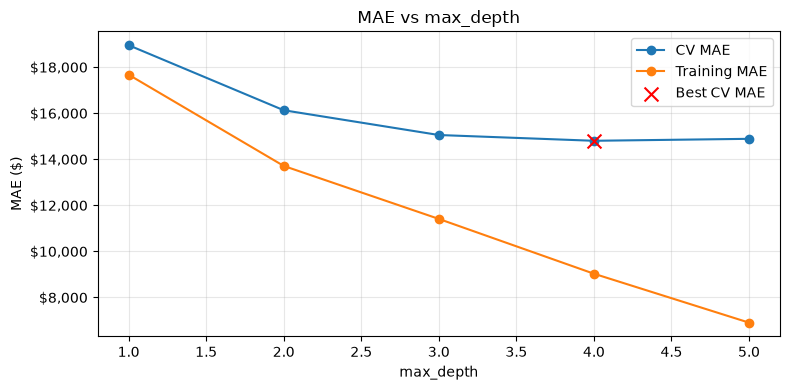

Best max_depth: 4
Best CV MAE: $14,794.49
Execution time: 00:00:25


In [11]:
sweep_max_depth = sweep_parameter(
    GradientBoostingRegressor,
    baseline_params,
    "max_depth",
    [1, 2, 3, 4, 5],
    n_repeats=1
)

Sweeping learning_rate: 100%|██████████| 5/5 [00:20<00:00,  4.17s/it]


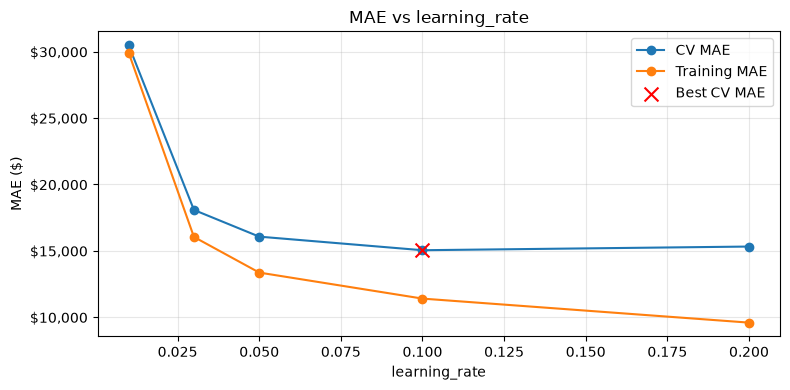

Best learning_rate: 0.1
Best CV MAE: $15,045.20
Execution time: 00:00:21


In [12]:
sweep_learning_rate = sweep_parameter(
    GradientBoostingRegressor,
    baseline_params,
    "learning_rate",
    [0.01, 0.03, 0.05, 0.1, 0.2],
    n_repeats=1
)

Sweeping min_samples_leaf: 100%|██████████| 5/5 [00:21<00:00,  4.25s/it]


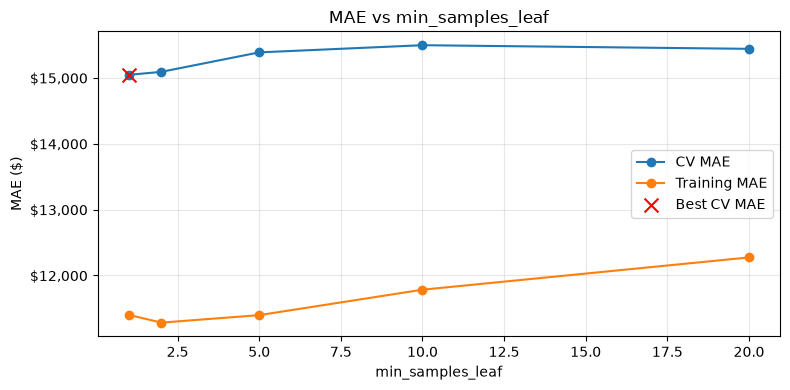

Best min_samples_leaf: 1
Best CV MAE: $15,045.20
Execution time: 00:00:21


In [13]:
sweep_min_samples_leaf = sweep_parameter(
    GradientBoostingRegressor,
    baseline_params,
    "min_samples_leaf",
    [1, 2, 5, 10, 20],
    n_repeats=1
)

Sweeping subsample: 100%|██████████| 5/5 [00:18<00:00,  3.63s/it]


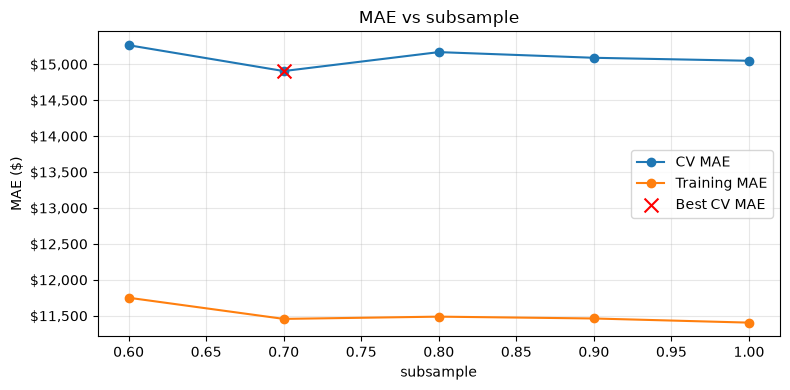

Best subsample: 0.7
Best CV MAE: $14,902.09
Execution time: 00:00:18


In [14]:
sweep_subsample = sweep_parameter(
    GradientBoostingRegressor,
    baseline_params,
    "subsample",
    [0.6, 0.7, 0.8, 0.9, 1.0],
    n_repeats=1
)

Sweeping n_estimators: 100%|██████████| 5/5 [00:59<00:00, 11.81s/it]


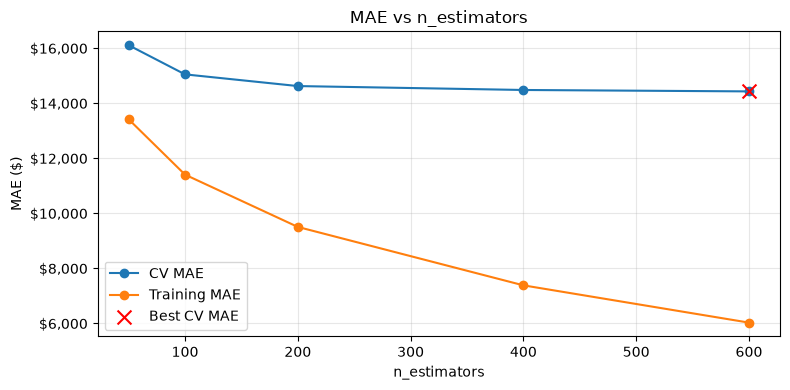

Best n_estimators: 600
Best CV MAE: $14,426.67
Execution time: 00:00:59


In [15]:
sweep_n_estimators = sweep_parameter(
    GradientBoostingRegressor,
    baseline_params,
    "n_estimators",
    [50, 100, 200, 400, 600],
    n_repeats=1
)

In [16]:
 # Your answer here

a2a = sweep_n_estimators["best_value"]

In [17]:
# DO NOT change this cell in any way

print(f'a2a = {a2a}')

a2a = 600


In [18]:
 # Your answer here

a2b = sweep_max_depth["best_value"]

In [19]:
# DO NOT change this cell in any way

print(f'a2b = {a2b}')

a2b = 4


In [20]:
 # Your answer here

a2c = sweep_learning_rate["best_value"]

In [21]:
# DO NOT change this cell in any way

print(f'a2c = {a2c:.4f}')

a2c = 0.1000


In [22]:
 # Your answer here

a2d = sweep_min_samples_leaf["best_value"]

In [23]:
# DO NOT change this cell in any way

print(f'a2d = {a2d}')

a2d = 1


In [24]:
 # Your answer here

a2e = sweep_subsample["best_value"]

In [25]:
# DO NOT change this cell in any way

print(f'a2e = {a2e:.4f}')

a2e = 0.7000


## Problem 3: Exploring Hyperparameter Combinations with `RandomizedSearchCV`

In Problem 2, we investigated five important hyperparameters of `GradientBoostingRegressor` using **independent manual sweeps**. Each experiment varied one parameter while holding the others at their default values.

However, hyperparameters can **interact**. For example, a smaller `learning_rate` may produce better results when combined with a larger number of boosting stages (`n_estimators`). Independent sweeps cannot fully explore these interactions.

We will now introduce **`RandomizedSearchCV`**, which evaluates randomly selected combinations of hyperparameters from specified distributions. Rather than testing every possible combination, randomized search samples a limited number of configurations, making it an efficient way to explore a large hyperparameter space.

Our goal is to identify promising combinations that we can refine using `GridSearchCV` in Problem 4.

### What You Need to Do

In this problem, **you will write the Python code** to define the hyperparameter distributions, configure and run `RandomizedSearchCV`, and examine the results. You may refer to examples from the Week 7 lesson notebook.

The problem has three parts:

- **Part A:** Define the hyperparameter search space.
- **Part B:** Configure and run randomized search.
- **Part C:** Examine the results and compare them with your previous experiments.

### Part A: Define the Search Space

Create a dictionary called `param_dist` containing the following distributions, informed by the manual sweeps in Problem 2.

| Hyperparameter | Distribution | Values explored |
|---|---|---|
| `n_estimators` | `randint(200, 1201)` | Integers from 200 to 1200 |
| `max_depth` | `randint(2, 6)` | Integers from 2 to 5 |
| `learning_rate` | `uniform(0.015, 0.135)` | Continuous values from 0.015 to 0.15 |
| `min_samples_leaf` | `randint(1, 11)` | Integers from 1 to 10 |
| `subsample` | `uniform(0.6, 0.4)` | Continuous values from 0.6 to 1.0 |

**Important:** The two distributions use their arguments differently:

- `randint(a, b)` samples integers from `a` through `b - 1`.
- `uniform(a, b)` samples continuous values from `a` up to (but not including) `a + b`. The second argument is the *width* of the interval, not its upper bound.

You will need `randint` and `uniform` from `scipy.stats`.

### Part B: Run Randomized Search

Create a `RandomizedSearchCV` object using the following settings:

| Setting | Value |
|---|---|
| Estimator | `GradientBoostingRegressor(random_state=random_seed)` |
| Parameter distributions | `param_dist` from Part A |
| Number of iterations | `n_iter=150` |
| Cross-validation | `RepeatedKFold(n_splits=5, n_repeats=1, random_state=random_seed)` |
| Scoring | `"neg_mean_absolute_error"` |
| Random seed | `random_state=random_seed` |
| Parallel processing | `n_jobs=-1` |

Fit the search object using `X_train` and `y_train`.

With 150 randomly sampled combinations and 5-fold cross-validation, the search will perform **750 cross-validation fits**, plus a final refit of the best model on the full training set.

**Do not use the held-out test set.** As in previous homeworks, the test set must remain untouched until final model evaluation.

Randomized search may take several minutes to complete, depending on your computer. You do not need to increase the number of iterations or CV repeats.

### Part C: Examine and Compare the Results

After the search completes:

1. Display the best hyperparameter combination using `rand_search.best_params_`.
2. Report the best CV MAE, converting `rand_search.best_score_` from negative MAE to a positive number in dollars.
3. Display the number of hyperparameter combinations evaluated.
4. Use the supplied `show_top_results()` function to display the **10 best configurations**, including their CV MAE and standard deviation.
5. Compare the best randomized-search CV MAE with the baseline from Problem 1 and the best result from the independent manual sweeps in Problem 2.

**Examine the top 10 configurations.** Do you notice patterns in the values of `learning_rate`, `n_estimators`, or other hyperparameters? Are the best configurations clustered in particular regions, or do several substantially different combinations produce similar CV MAE?

Did randomized search improve upon the baseline and the best manual sweep? If so, by how much?

Remember that randomized search is not guaranteed to discover the globally optimal configuration. Its advantage is that it can explore combinations across several hyperparameters without evaluating every possible combination.

We will use the most promising configuration to construct a focused grid search in Problem 4.

### Problem 3 Graded Answers

Set the following variables using expressions based on your search results:

- `a3a`: The number of hyperparameter combinations evaluated.
- `a3b`: The best CV MAE found by `RandomizedSearchCV`, expressed as a positive number in dollars.

Use attributes of your fitted search object rather than manually entering the numerical answers.

In [26]:
# Your code here; add as many cells as you need

param_dist = {
    "n_estimators": randint(200, 1201),
    "max_depth": randint(2, 6),
    "learning_rate": uniform(0.015, 0.135),
    "min_samples_leaf": randint(1, 11),
    "subsample": uniform(0.6, 0.4)
}



In [27]:
cv = RepeatedKFold(
    n_splits=5,
    n_repeats=1,
    random_state=random_seed
)

In [28]:
rand_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(random_state=random_seed),
    param_distributions=param_dist,
    n_iter=150,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=random_seed,
    n_jobs=-1
)

In [29]:
rand_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': <scipy.stats....x704b42bd3b60>, 'max_depth': <scipy.stats....x704b42a087d0>, 'min_samples_leaf': <scipy.stats....x704b42969950>, 'n_estimators': <scipy.stats....x704b42d61400>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",150
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",RepeatedKFold...ndom_state=42)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the 

In [30]:
print(rand_search.best_params_)
print(f"Best CV MAE: ${-rand_search.best_score_:,.2f}")
print(f"Number of combinations: {len(rand_search.cv_results_['params'])}")

show_top_results(rand_search)

{'learning_rate': np.float64(0.03995535149594615), 'max_depth': 4, 'min_samples_leaf': 2, 'n_estimators': 929, 'subsample': np.float64(0.7799016533479063)}
Best CV MAE: $14,040.49
Number of combinations: 150


,learning_rate,max_depth,min_samples_leaf,n_estimators,subsample,CV MAE,CV Std Dev
Rank,,,,,,,
1,0.0400,4,2,929,0.7799,"$14,040.49","$1,497.23"
2,0.0196,3,1,1131,0.6729,"$14,105.43","$1,410.53"
3,0.0259,5,1,966,0.9213,"$14,136.40","$1,447.28"
4,0.0521,4,1,938,0.6478,"$14,142.29","$1,440.94"
5,0.0200,4,1,604,0.6226,"$14,147.11","$1,395.83"
6,0.0533,3,2,905,0.8768,"$14,151.19","$1,490.05"
7,0.0517,4,9,827,0.7410,"$14,207.14","$1,330.32"
8,0.0541,3,2,881,0.9232,"$14,222.15","$1,384.26"
9,0.0867,3,6,615,0.8371,"$14,224.14","$1,344.45"


In [31]:
 # Your answer here

a3a = len(rand_search.cv_results_["params"])

In [32]:
# DO NOT change this cell in any way

print(f'a3a = {a3a}')

a3a = 150


In [33]:
 # Your answer here

a3b = -rand_search.best_score_

In [34]:
# DO NOT change this cell in any way

print(f'a3b = ${a3b:,.2f}')

a3b = $14,040.49


## Problem 4: Refining Hyperparameters with `GridSearchCV`

In Problem 3, we used `RandomizedSearchCV` to explore combinations of five hyperparameters. By sampling from relatively broad distributions, we identified a promising configuration without examining every possible combination.

We will now use **`GridSearchCV`** to refine that result.

Unlike randomized search, which samples combinations randomly, grid search evaluates **every combination** of the specified parameter values. This makes grid search particularly useful when we have already identified a promising region and want to investigate it more systematically.

Our goal is to determine whether a focused grid search can improve upon the best result from Problem 3.

### What You Need to Do

In this problem, **you will write the Python code** to define a focused parameter grid, configure and run `GridSearchCV`, and compare its results with randomized search.

The problem has two parts:

- **Part A:** Construct a focused parameter grid.
- **Part B:** Run grid search and examine the results.

### Part A: Construct a Focused Parameter Grid

Begin by examining `rand_search.best_params_` from Problem 3.

We will refine three hyperparameters:

- `n_estimators`
- `learning_rate`
- `max_depth`

Use the following parameter grid, which explores a region around the promising values identified by randomized search:

| Hyperparameter | Grid values |
|---|---|
| `n_estimators` | `[700, 850, 1000, 1150, 1300]` |
| `learning_rate` | `[0.02, 0.03, 0.04, 0.05, 0.06]` |
| `max_depth` | `[3, 4, 5]` |

Hold the remaining two hyperparameters, `min_samples_leaf` and `subsample`, fixed at their best values from randomized search, using `rand_search.best_params_`.

The grid contains:

$$
5 \times 5 \times 3 = 75
$$

hyperparameter combinations.

**Important:** Use the specified grid values rather than choosing your own. This will make your results reproducible and allow us to compare experiments consistently.

### Part B: Run Grid Search

Create a `GridSearchCV` object using the following settings:

| Setting | Value |
|---|---|
| Estimator | `GradientBoostingRegressor` with `random_state=random_seed` and the two fixed hyperparameters from Part A |
| Parameter grid | `param_grid` from Part A |
| Cross-validation | `RepeatedKFold(n_splits=5, n_repeats=1, random_state=random_seed)` |
| Scoring | `"neg_mean_absolute_error"` |
| Parallel processing | `n_jobs=-1` |

Fit the grid search using `X_train` and `y_train`.

With 75 parameter combinations and 5-fold cross-validation, the search requires **375 cross-validation fits**, plus the final refit of the best model on the complete training set.

Do not use the held-out test set.

### Examine and Compare the Results

After the search completes:

1. Display the best hyperparameter combination using `grid_search.best_params_`.
2. Report the best CV MAE, converting `grid_search.best_score_` to a positive number in dollars.
3. Display the number of combinations evaluated and the execution time.
4. Use the supplied `show_top_results()` function to display the **10 best hyperparameter combinations**, including their CV MAE and standard deviation.
5. Compare the best grid-search CV MAE with the best randomized-search CV MAE from Problem 3.

**Examine the top 10 configurations.** Do you notice any patterns in the hyperparameter values? Are several configurations producing nearly identical CV MAE? Pay particular attention to the relationship between `learning_rate` and `n_estimators`.

Did grid search improve upon randomized search? If so, by how much? Was the improvement substantial relative to the additional computational effort?

**Pay particular attention to whether the best parameter values lie at the boundaries of your grid.** What does this suggest about the possibility of improving the model further? Does it necessarily mean you should expand the search again?

Remember that grid search is not guaranteed to outperform randomized search. Its purpose is to investigate a promising region more thoroughly, and its effectiveness depends on the grid you choose.

We will return to these observations in the reflection question in Problem 7.

### Problem 4 Graded Answers

Set the following variables using expressions based on your grid-search results:

- `a4a`: The number of hyperparameter combinations evaluated.
- `a4b`: The best CV MAE found by `GridSearchCV`, expressed as a positive number in dollars.

Use attributes of your fitted search object rather than manually entering the numerical answers.

In Problem 5, you will compare the baseline, randomized-search, and grid-search configurations and select your final model.

In [35]:
# Your code here; add as many cells as you need

best_min_samples_leaf = rand_search.best_params_["min_samples_leaf"]
best_subsample = rand_search.best_params_["subsample"]

In [36]:
param_grid = {
    "n_estimators": [700, 850, 1000, 1150, 1300],
    "learning_rate": [0.02, 0.03, 0.04, 0.05, 0.06],
    "max_depth": [3, 4, 5]
}

In [37]:
grid_model = GradientBoostingRegressor(
    random_state=random_seed,
    min_samples_leaf=best_min_samples_leaf,
    subsample=best_subsample
)

In [38]:
cv_grid = RepeatedKFold(
    n_splits=5,
    n_repeats=1,
    random_state=random_seed
)

In [39]:
grid_search = GridSearchCV(
    estimator=grid_model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv_grid,
    n_jobs=-1
)


In [40]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...016533479063))
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.02, 0.03, ...], 'max_depth': [3, 4, ...], 'n_estimators': [700, 850, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",RepeatedKFold...ndom_state=42)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable

In [42]:
print(grid_search.best_params_)
print(f"Best CV MAE: ${-grid_search.best_score_:,.2f}")
print(f"Number of combinations: {len(grid_search.cv_results_['params'])}")

show_top_results(grid_search)

{'learning_rate': 0.02, 'max_depth': 4, 'n_estimators': 1300}
Best CV MAE: $13,905.20
Number of combinations: 75


,learning_rate,max_depth,n_estimators,CV MAE,CV Std Dev
Rank,,,,,
1,0.0200,4,1300,"$13,905.20","$1,392.82"
2,0.0300,3,1300,"$13,940.22","$1,437.26"
3,0.0200,4,1150,"$13,942.56","$1,409.50"
4,0.0400,4,1300,"$13,954.93","$1,484.62"
5,0.0400,3,1300,"$13,955.65","$1,393.59"
6,0.0200,4,1000,"$13,965.91","$1,422.89"
7,0.0300,4,1300,"$13,968.31","$1,500.33"
8,0.0400,4,1150,"$13,969.91","$1,484.01"
9,0.0400,4,1000,"$13,971.48","$1,493.03"


In [43]:
 # Your answer here

a4a = len(grid_search.cv_results_["params"])


In [44]:
# DO NOT change this cell in any way

print(f'a4a = {a4a}')

a4a = 75


In [45]:
 # Your answer here

a4b = -grid_search.best_score_

In [46]:
# DO NOT change this cell in any way

print(f'a4b = ${a4b:,.2f}')

a4b = $13,905.20


## Problem 5: Selecting and Evaluating Your Final Model

In the preceding problems, we explored several approaches to improving the performance of `GradientBoostingRegressor`:

- **Problem 1:** Established a baseline using default hyperparameters.
- **Problem 2:** Used independent manual sweeps to investigate individual hyperparameters.
- **Problem 3:** Used `RandomizedSearchCV` to explore combinations of hyperparameters.
- **Problem 4:** Used `GridSearchCV` to refine a promising region identified by randomized search.

We will now **compare our candidate models, select the best configuration using cross-validation, and evaluate it on the held-out test set**.

### What You Need to Do

You will write Python code to complete three tasks:

- **Part A:** Compare three candidate models using cross-validation.
- **Part B:** Select and train your final model.
- **Part C:** Evaluate the final model on the held-out test set.

### Part A: Compare Candidate Models

Consider the following three candidates:

| Model | Description | Hyperparameters |
|---|---|---|
| 1 | Baseline | Default hyperparameters from Problem 1 |
| 2 | Randomized search | Best parameters from Problem 3 |
| 3 | Grid search | Best parameters from Problem 4, including the two parameters held fixed |

We will compare these three **fixed hyperparameter configurations**, rather than repeating the randomized or grid searches.

To make a consistent comparison, evaluate each candidate using `run_model()` with `n_repeats=3`. This performs three repetitions of 5-fold cross-validation.

Create a comparison table reporting:

- Mean CV MAE
- Standard deviation of CV MAE
- Training MAE

Examine the differences between training and CV MAE. Does the model with the lowest training error also have the lowest CV error?

**Important:** For the grid-search candidate, `grid_search.best_params_` contains only the three parameters included in the grid. You must also include the fixed values of `min_samples_leaf` and `subsample` inherited from randomized search.

**Select the candidate with the lowest mean CV MAE.** Even if two candidates have similar results, use this rule consistently. We will consider whether the differences are meaningful in the reflection questions.

Do not use the test set to select your model.

### Part B: Select and Train the Final Model

Using the comparison table from Part A:

1. Identify the candidate with the lowest mean CV MAE.
2. Retrieve its complete set of hyperparameters.
3. Instantiate a new `GradientBoostingRegressor` using those parameters, including `random_state=random_seed`.
4. Fit the new model on the **complete training set** (`X_train`, `y_train`).

Display the selected model number, its hyperparameters, and its mean CV MAE.

Remember that we are selecting a model **configuration** using cross-validation and then fitting a fresh model with that configuration on all the available training data.

### Part C: Evaluate on the Held-Out Test Set

Using the model trained in Part B:

1. Generate predictions for `X_test`.
2. Compute the test MAE using `mean_absolute_error(y_test, predictions)`.
3. Display the test MAE in dollars.
4. Compare the test MAE with the mean CV MAE of your selected model.

**Important:** Do not use `run_model()` on the test set. That function performs cross-validation and fits models internally. You must explicitly fit your final model on the training data and evaluate it **once** on the held-out test data.

The test MAE provides our final estimate of how well the selected model will perform on new, unseen data.

### Problem 5 Graded Answers

Set the following variables:

- `a5a`: The model selected using the lowest mean CV MAE:
  - `1` = Baseline model
  - `2` = Randomized-search model
  - `3` = Grid-search model
- `a5b`: The final test MAE, expressed as a positive number in dollars.

Use Python expressions or variables based on your computed results rather than manually entering the numerical answers.

### Conceptual Reminder

**Cross-validation is used for model selection. The held-out test set is used only after model selection, to estimate generalization performance.**

The model with the lowest CV MAE is not guaranteed to have the lowest test MAE. Differences between CV and test performance are expected, especially when candidate models have similar CV scores.

Also, a lower training MAE does not necessarily imply better generalization. This is one reason we rely on cross-validation rather than training performance when selecting our final model.

In [47]:
# Your code here; add as many cells as you need

grid_params = grid_search.best_params_.copy()
grid_params["min_samples_leaf"] = rand_search.best_params_["min_samples_leaf"]
grid_params["subsample"] = rand_search.best_params_["subsample"]

In [49]:
random_params = rand_search.best_params_.copy()

grid_params = grid_search.best_params_.copy()
grid_params["min_samples_leaf"] = rand_search.best_params_["min_samples_leaf"]
grid_params["subsample"] = rand_search.best_params_["subsample"]

In [50]:
baseline_cv, baseline_std, baseline_train = run_model(
    GradientBoostingRegressor,
    X_train,
    y_train,
    n_repeats=3,
    **baseline_params
)

random_cv, random_std, random_train = run_model(
    GradientBoostingRegressor,
    X_train,
    y_train,
    n_repeats=3,
    **random_params
)

grid_cv, grid_std, grid_train = run_model(
    GradientBoostingRegressor,
    X_train,
    y_train,
    n_repeats=3,
    **grid_params
)

In [51]:
comparison = pd.DataFrame({
    "Model": [1, 2, 3],
    "Description": ["Baseline", "Randomized Search", "Grid Search"],
    "Mean CV MAE": [baseline_cv, random_cv, grid_cv],
    "CV Std Dev": [baseline_std, random_std, grid_std],
    "Training MAE": [baseline_train, random_train, grid_train]
})

comparison

,Model,Description,Mean CV MAE,CV Std Dev,Training MAE
0,1,Baseline,14980.756748,917.863339,11402.013336
1,2,Randomized Search,13823.787257,1098.063958,4400.923048
2,3,Grid Search,13731.269178,985.094838,5762.343603


In [52]:
best_index = comparison["Mean CV MAE"].idxmin()
selected_model_number = int(comparison.loc[best_index, "Model"])
selected_cv_mae = comparison.loc[best_index, "Mean CV MAE"]

In [53]:
if selected_model_number == 1:
    final_params = baseline_params.copy()
elif selected_model_number == 2:
    final_params = random_params.copy()
else:
    final_params = grid_params.copy()

In [54]:
final_model = GradientBoostingRegressor(
    random_state=random_seed,
    **final_params
)

In [55]:
final_model.fit(X_train, y_train)


,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.02
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",1300
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",np.float64(0.7799016533479063)
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values mu

In [56]:
test_predictions = final_model.predict(X_test)

In [57]:
test_mae = mean_absolute_error(y_test, test_predictions)

In [58]:
print(f"Selected model: {selected_model_number}")
print(f"Selected parameters: {final_params}")
print(f"Mean CV MAE: ${selected_cv_mae:,.2f}")
print(f"Test MAE: ${test_mae:,.2f}")

Selected model: 3
Selected parameters: {'learning_rate': 0.02, 'max_depth': 4, 'n_estimators': 1300, 'min_samples_leaf': 2, 'subsample': np.float64(0.7799016533479063)}
Mean CV MAE: $13,731.27
Test MAE: $13,707.29


In [59]:
 # Your answer here

a5a = selected_model_number

In [60]:
# DO NOT change this cell in any way

print(f'a5a = {a5a}')

a5a = 3


In [61]:
 # Your answer here

a5b = test_mae

In [62]:
# DO NOT change this cell in any way

print(f'a5b = ${a5b:,.2f}')

a5b = $13,707.29


## Problem 6: Multiple-Choice Questions

For each question, select the single best answer (1, 2, 3, or 4) and assign it to the corresponding variable (`a6a` through `a6e`).

### Part A: How Gradient Boosting Works

What is the primary role of each new decision tree added to a gradient boosting ensemble?

1. To predict independently of all previous trees, with predictions combined by majority vote.
2. To correct errors made by the current ensemble by fitting information derived from the loss function.
3. To replace the previous tree whenever the new tree achieves lower training error.
4. To train on a randomly selected subset of features without considering previous predictions.

In [63]:
# Your answer here. 

a6a = 2

In [64]:
### Do not change this cell in any way

print(f'a6a = {a6a}')

a6a = 2


### Part B: Interacting Hyperparameters

In Problem 2, you investigated `learning_rate` and `n_estimators` independently. Why might the best combination of these parameters differ from the best values found in the separate sweeps?

1. `learning_rate` determines the number of features available to each tree.
2. `n_estimators` affects only computational cost, not model predictions.
3. The two parameters are independent, so their individually optimal values must also be optimal when combined.
4. A smaller `learning_rate` often requires more boosting stages to achieve comparable or better predictive performance.


In [65]:
# Your answer here. 

a6b = 4

In [66]:
### Do not change this cell in any way

print(f'a6b = {a6b}')

a6b = 4


### Part C: Diminishing Returns and Early Stopping

During a sweep of `n_estimators`, training MAE continues to decrease steadily as more boosting stages are added. However, CV MAE improves initially and then levels off, with only very small fluctuations and no clear upward trend.

Why might it be reasonable to stop increasing `n_estimators` rather than continue until CV MAE actually begins to increase?

1. The additional trees increase computational cost and model complexity, while tiny observed CV improvements may be too small to distinguish from validation variability.
2. Once CV MAE reaches a plateau, additional boosting stages cannot change the model's predictions.
3. Continuing to add trees will necessarily cause CV MAE to increase eventually.
4. Training MAE should stop decreasing when CV MAE reaches its minimum, so the observed behavior indicates an error in the experiment.


In [67]:
# Your answer here. 

a6c = 1

In [68]:
### Do not change this cell in any way

print(f'a6c = {a6c}')

a6c = 1


### Part D: Interpreting Cross-Validation Variability

Two gradient boosting configurations have the following cross-validation results:

| Model | Mean CV MAE | CV standard deviation |
| ----- | ----------- | --------------------- |
| A     | $14,100     | $1,200                |
| B     | $14,080     | $1,250                |

Which conclusion is most appropriate?

1. Model B is guaranteed to generalize better because its mean CV MAE is $20 lower.
2. Model A must be selected because its CV standard deviation is lower.
3. Both models must have identical test MAE because their CV scores are similar.
4. The difference in mean CV MAE is very small relative to fold-to-fold variability, so the results provide little evidence of a meaningful improvement.



In [69]:
# Your answer here. 

a6d = 4

In [70]:
### Do not change this cell in any way

print(f'a6d = {a6d}')

a6d = 4


### Part E: Model Selection and Test Evaluation

Suppose your grid-search model achieves a slightly lower CV MAE than your randomized-search model, but the difference is small relative to the variation across CV folds.

Which conclusion is most appropriate?

1. The grid-search model is guaranteed to achieve a lower MAE on the held-out test set.
2. The observed improvement may not be meaningful; select a model using the specified CV-based procedure, then use the held-out test set for final evaluation.
3. The randomized-search model must be preferable because it required fewer evaluations.
4. Evaluate both models on the test set repeatedly and select whichever produces the lower test MAE.


In [71]:
# Your answer here. 

a6e = 2

In [72]:
### Do not change this cell in any way

print(f'a6e = {a6e}')

a6e = 2


## Problem 7: Reflection — When Is a Better Model Worth the Effort?

In this homework, you began with a baseline gradient boosting model, explored individual hyperparameters through manual sweeps, and then used randomized search and grid search to find increasingly promising configurations.

Each approach involved a tradeoff between **predictive performance, computational cost, and model complexity**.

Imagine that you are working as a machine learning engineer developing a house-price prediction system. Your manager asks whether the company should invest additional computing resources in further hyperparameter tuning.

Write a short reflection (approximately **150–250 words**) addressing the following:

1. **What did you gain?** Compare the CV MAE of your baseline, randomized-search, and grid-search models. How much improvement did the more sophisticated searches actually provide?

2. **What did it cost?** Consider the number of configurations evaluated and the execution times of your searches. Did grid search provide enough additional improvement to justify its computational expense?

3. **When would you stop?** Suppose you could continue experimenting with larger grids, more randomized trials, or additional boosting stages. What evidence would convince you that further tuning is no longer worthwhile, even if training MAE continues to decrease?

4. **What would you recommend?** Would you deploy your selected model now, return to a simpler configuration, or invest in further tuning? Explain your decision using evidence from your experiments.

There is no single correct recommendation. Your answer should demonstrate that you understand the tradeoffs and can support a practical decision with quantitative evidence.

**Important:** Do not use the held-out test set to compare or select alternative models. Your recommendation should be based on the cross-validation results and computational costs observed during tuning.

In [73]:
# Your answer here, NOT in the next cell

a7 = """
The tuning process improved the model a bit, but made the professor's point that sometimes the additional effort may not be worth it. The baseline model CV MAE of $15,031. 
That was improved by the randomized search and grid search, but improvements became smaller with each approach.

If the time it takes to run = cost, there was a significant cost. These additional approaches took much longer (randomized search = 43 minutes!) and only improved the CV MAE by ~ $135.

I would stop tuning when the additional searches produce small improvements relative to the normal variation in cross-validation results. Does the additonal complexity and compute cost
produce business value?

Based on the results, I would use the selected grid-search model. It had a strong cross-validation performance and improvements after that seemed to have diminishing returns.
"""

In [74]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print("a7 =")
print(a7)

a7 =

The tuning process improved the model a bit, but made the professor's point that sometimes the additional effort may not be worth it. The baseline model CV MAE of $15,031. 
That was improved by the randomized search and grid search, but improvements became smaller with each approach.

If the time it takes to run = cost, there was a significant cost. These additional approaches took much longer (randomized search = 43 minutes!) and only improved the CV MAE by ~ $135.

I would stop tuning when the additional searches produce small improvements relative to the normal variation in cross-validation results. Does the additonal complexity and compute cost
produce business value?

Based on the results, I would use the selected grid-search model. It had a strong cross-validation performance and improvements after that seemed to have diminishing returns.



## Appendix 1: Important `GradientBoostingRegressor` Hyperparameters

`GradientBoostingRegressor` has numerous hyperparameters controlling how the ensemble learns, how complex its individual trees can become, and how strongly it fits the training data.

In this homework, we focus on five important hyperparameters:

| Hyperparameter | Default | What it controls |
|---|---|---|
| `n_estimators` | `100` | Number of boosting stages (trees). More stages can improve performance but increase training time and may eventually cause overfitting. |
| `learning_rate` | `0.1` | Contribution of each new tree. Smaller values generally require more boosting stages. |
| `max_depth` | `3` | Maximum depth of individual trees. Deeper trees capture more complex relationships but may overfit. |
| `min_samples_leaf` | `1` | Minimum number of samples in a leaf. Larger values restrict tree complexity. |
| `subsample` | `1.0` | Fraction of training examples used for each boosting stage. Values below 1.0 introduce randomness and can improve generalization. |

### Other Useful Hyperparameters

You may encounter several others when working with gradient boosting:

| Hyperparameter | Default | Purpose |
|---|---|---|
| `max_features` | `None` | Number of features considered when finding each split |
| `min_samples_split` | `2` | Minimum number of samples needed to split a node |
| `max_leaf_nodes` | `None` | Maximum number of leaf nodes in each tree |
| `loss` | `"squared_error"` | Loss function minimized during boosting |

**Important interaction:** `learning_rate` and `n_estimators` often need to be tuned together. Reducing the learning rate makes each tree contribute less, so more boosting stages may be needed to obtain good predictive performance.

This is one reason why the best values found through independent manual sweeps may not form the best overall combination.

## Appendix 2: Practical Guide to Hyperparameter Tuning and Model Selection

Hyperparameter tuning is not simply a matter of finding the lowest numerical error. Effective tuning also requires interpreting validation results, controlling computational cost, and avoiding overfitting.

### 1. Interpreting Training and Cross-Validation Curves

When examining the plots produced by `sweep_parameter()`, look for three common patterns:

| Pattern | Interpretation |
|---|---|
| Training and CV MAE are both high | The model may be underfitting |
| Training MAE decreases and CV MAE also decreases | Additional complexity appears to improve generalization |
| Training MAE continues decreasing while CV MAE plateaus or increases | Additional complexity is providing diminishing returns or may be causing overfitting |

**A plateau is important.** You do not need to wait until CV MAE increases to stop adding complexity. If additional trees produce negligible improvements in CV MAE, the extra computational expense may not be justified.

Small differences in CV MAE may also reflect variability in the validation folds rather than meaningful differences in generalization.

### 2. Choosing a Search Strategy

Different stages of tuning call for different methods:

| Method | Best used for | Limitation |
|---|---|---|
| Manual sweeps | Understanding individual hyperparameters and identifying promising ranges | Cannot fully explore interactions |
| `RandomizedSearchCV` | Sampling combinations from a broad search space with a fixed computational budget | May miss promising configurations |
| `GridSearchCV` | Systematically investigating a small, focused set of combinations | Computational cost grows rapidly with the number of values and parameters |

A useful workflow is:

1. Establish a baseline model.
2. Explore individual hyperparameters with independent manual sweeps.
3. Use randomized search to investigate combinations.
4. Optionally refine promising values with a focused grid search.
5. Compare candidate configurations using a consistent cross-validation procedure.
6. Select the final configuration and evaluate it once on the held-out test set.

Grid search is not guaranteed to improve upon randomized search. Sometimes the additional computation produces little or no benefit.

### 3. Using Cross-Validation Efficiently

Repeated cross-validation can reduce the influence of a particular partition of the data, but it also increases computational cost.

For this homework:

- **Manual sweeps:** One repetition of 5-fold CV.
- **Randomized and grid search:** One repetition of 5-fold CV.
- **Final candidate comparison:** Three repetitions of 5-fold CV.

More repetitions are not automatically better. The appropriate computational budget depends on the dataset, the model, and how much additional precision is needed.

The standard deviation of CV scores describes variation across validation folds. It is useful context but is not, by itself, a measure of the statistical significance of differences between models.

### 4. Protecting the Test Set

**Use cross-validation for hyperparameter tuning and model selection. Use the held-out test set only for final evaluation.**

Repeatedly examining test results and using them to change hyperparameters compromises the independence of the test set.

Once the final configuration is selected:

1. Instantiate a fresh model with the chosen hyperparameters.
2. Fit it on the full training dataset.
3. Predict on the held-out test dataset.
4. Compute and report the test MAE.

The model with the lowest training MAE, or even the lowest observed CV MAE, is not guaranteed to achieve the lowest test MAE.

### 5. Practical Tips

- Record hyperparameter configurations and CV results so experiments are reproducible.
- Pay attention to the numerical scale of plots; visually small differences may or may not be meaningful.
- Use `n_jobs=-1` to parallelize cross-validation when your computer has sufficient resources.
- If parallel processing causes memory problems, reduce `n_jobs`.
- Balance small improvements in CV MAE against additional training time and model complexity.